# 04 — Tuning, ngưỡng và so sánh ứng viên trên Validation
So sánh Default, Tuned, Soft Voting và Hard Voting trên cùng cache sau Top-K.
Chỉ notebook 05 đánh giá Test. Không đọc artifacts production.
Tiêu chí hiện tại: đạt Recall mục tiêu, tối đa Accuracy rồi F1; nếu không đạt, ưu tiên Recall.
Điều này khác mô tả max F1/F2 trong tài liệu cũ; bảng dưới báo đầy đủ cả Accuracy, F1 và F2.


In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT/'src').is_dir(): PROJECT_ROOT=PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0,str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display
from src.config import NOTEBOOK_SAVED_MODELS_DIR, NOTEBOOK_METRICS_DIR, FBETA_BETA, THRESHOLD_GRID_POINTS, PROCESSED_DATA_DIR
from src.models.persistence import load_spam_pipeline, save_spam_pipeline
from src.models.classifiers import LogisticRegressionFromScratch, LinearSVMFromScratch, NaiveBayesClassifier
from src.models.ensemble import SpamVotingEnsemble
from src.models.tuning import tune_model_hyperparameters, ThresholdOptimizerScratch, ModelSelectionWorkflow
from src.evaluation.metrics import SpamModelEvaluator
from src.evaluation.visualization import plot_threshold_sensitivity_curve
artifacts=load_spam_pipeline(NOTEBOOK_SAVED_MODELS_DIR/'feature_artifacts.joblib')
baseline_bundle=load_spam_pipeline(NOTEBOOK_SAVED_MODELS_DIR/'baseline_models.joblib')
run_id=artifacts['run_id']
assert run_id == baseline_bundle['run_id'] == (PROCESSED_DATA_DIR/'notebook_run_id.txt').read_text(encoding='utf-8').strip(), 'Chạy lại 02 rồi 03.'
config=artifacts['config']
X_train=sp.load_npz(PROCESSED_DATA_DIR/'X_train.npz'); y_train=np.load(PROCESSED_DATA_DIR/'y_train.npy')
X_val=sp.load_npz(PROCESSED_DATA_DIR/'X_val.npz'); y_val=np.load(PROCESSED_DATA_DIR/'y_val.npy')
optimizer=ThresholdOptimizerScratch(config.recall_target,FBETA_BETA,THRESHOLD_GRID_POINTS)
evaluator=SpamModelEvaluator()

from hashlib import sha256
if not artifacts.get('cache_sha256'):
    raise RuntimeError('Cache thiếu manifest: chạy lại notebook 02–04.')
for filename, expected_hash in artifacts['cache_sha256'].items():
    actual_hash=sha256((PROCESSED_DATA_DIR/filename).read_bytes()).hexdigest()
    if actual_hash != expected_hash:
        raise RuntimeError(f'Cache không khớp artifacts: {filename}; chạy lại notebook 02–04.')
print('PASS: hash ma trận, nhãn và CSV khớp artifacts.')


PASS: hash ma trận, nhãn và CSV khớp artifacts.


## 1. Grid Search trên Validation
Tuning C/learning_rate cho LR, SVM và alpha cho Complement NB. Ngưỡng được tối ưu cho mỗi cấu hình.
Cột objective_score là Accuracy có ràng buộc Recall (hoặc điểm phạt khi không đạt), không gọi là F1.
Dùng lưới nhỏ để kiểm soát thời gian; giữ các baseline làm đối chứng.


In [2]:
grids = {
    'Logistic Regression': (LogisticRegressionFromScratch, {
        'C': [0.5, 1.0, 2.0], 'learning_rate': [0.1], 'max_iter': [200],
        'class_weight': ['balanced'], 'random_state': [config.random_state],
    }),
    'Linear SVM': (LinearSVMFromScratch, {
        'C': [0.5, 1.0, 2.0], 'learning_rate': [0.05], 'max_iter': [150],
        'class_weight': ['balanced'], 'loss': ['squared_hinge'], 'random_state': [config.random_state],
    }),
    'Complement Naive Bayes': (NaiveBayesClassifier, {
        'alpha': [0.5, 1.0, 2.0], 'kind': ['complement'],
    }),
}
tuned_models = {}
tuning_rows = []
tuned_params = {}
for name, (model_class, grid) in grids.items():
    print('Grid Search:', name, flush=True)
    model, params, objective = tune_model_hyperparameters(
        name, model_class, grid, X_train, y_train, X_val, y_val,
        recall_target=config.recall_target, threshold_optimizer=optimizer,
    )
    tuned_models[name] = model
    tuned_params[name] = params
    info = optimizer.select_best_threshold(optimizer.metrics_table(y_val, model.predict_proba(X_val)[:, 1]))
    tuning_rows.append({
        'model': name, 'best_params': str(params), 'objective_score': objective,
        **{key: info[key] for key in ('threshold', 'accuracy', 'precision', 'recall', 'f1', 'f2', 'target_met')}
    })
tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)
tuning_df.to_csv(NOTEBOOK_METRICS_DIR / 'hyperparameter_tuning.csv', index=False)


Grid Search: Logistic Regression
Grid Search: Linear SVM
Grid Search: Complement Naive Bayes
                    model  ... target_met
0     Logistic Regression  ...       True
1              Linear SVM  ...       True
2  Complement Naive Bayes  ...       True

[3 rows x 10 columns]


## 2. Default–Tuned–Soft/Hard Voting
Soft Voting tối ưu threshold trên Validation. Hard Voting giữ quy tắc đa số tại 0.5;
điểm của Hard Voting là tỷ lệ phiếu có trọng số, không phải xác suất đã calibration.
Không fit lại ensemble: các mô hình thành viên đã fit trên Train.


                    candidate_key  ... selected_as_final
0              Linear SVM (Tuned)  ...              True
1                      Linear SVM  ...             False
2     Logistic Regression (Tuned)  ...             False
3             Logistic Regression  ...             False
4                     Soft Voting  ...             False
5  Complement Naive Bayes (Tuned)  ...             False
6          Complement Naive Bayes  ...             False
7                     Hard Voting  ...             False

[8 rows x 17 columns]
Mô hình chọn trước khi mở Test: Linear SVM (Tuned)
Quy tắc: Max validation accuracy with recall >= 0.85


E:\Hoc_May_Tren_truong\lab_1 spam_classifier\src\evaluation\visualization.py:735: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


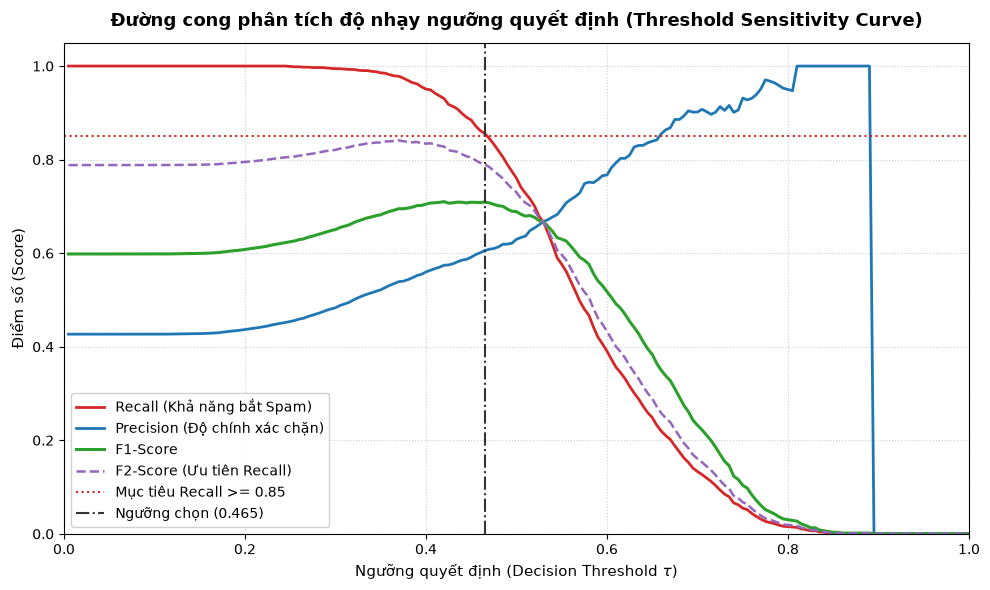

In [3]:
models={**baseline_bundle['models'], **{f'{name} (Tuned)':model for name,model in tuned_models.items()}}
for voting in ('soft','hard'):
    models[f'{voting.title()} Voting']=SpamVotingEnsemble(tuned_models, weights={name:1. for name in tuned_models}, voting=voting)
selections={}; scans={}; candidate_rows={}
for name,model in models.items():
    scores=model.predict_proba(X_val)[:,1]
    if getattr(model,'voting',None)=='hard':
        scan=optimizer.metrics_table(y_val,scores,thresholds=np.array([.5]))
    else:
        scan=optimizer.metrics_table(y_val,scores)
    info=optimizer.select_best_threshold(scan)
    selections[name]=info; scans[name]=scan
    candidate_rows[name]={
        'algorithm':name, 'branch':'Tuned' if name.endswith('(Tuned)') else ('Ensemble' if 'Voting' in name else 'Default'),
        'parameter_source':'Grid Search' if name.endswith('(Tuned)') else 'Pre-set',
        'params':tuned_params.get(name.removesuffix(' (Tuned)'),{}) if name.endswith('(Tuned)') else {},
        'threshold':info['threshold'], 'target_met':info['target_met'],
        'objective_score':info['accuracy'] if info['target_met'] else info['recall'],
        **{f'val_{key}':info[key] for key in ('accuracy','precision','recall','f1','f2')},
    }
workflow=ModelSelectionWorkflow(config.recall_target)
comparison=workflow.build_comparison_frame(candidate_rows)
winner_name=workflow.select_final_winner(comparison)
winner=models[winner_name]; winner_info=selections[winner_name]
display(comparison)
comparison.to_csv(NOTEBOOK_METRICS_DIR/'validation_model_selection.csv',index=False)
print('Mô hình chọn trước khi mở Test:',winner_name)
print('Quy tắc:',winner_info['selection_rule'])
plot_threshold_sensitivity_curve(scans[winner_name],recall_target=config.recall_target,selected_threshold=winner_info['threshold'])


## 3. Đóng gói đúng bộ biến đổi và thứ tự đặc trưng
Bundle mang run_id, source_ids, builder, selected_indices, các ứng viên và threshold đã chốt.
Chưa có metrics Test; notebook 05 sẽ tính từ đầu và xuất kết quả cùng run_id.


In [4]:
pipeline_bundle={**artifacts,'model':winner,'model_name':winner_name,'best_threshold':float(winner_info['threshold']),
    'validation_metrics':winner_info,'candidate_models':models,'candidate_thresholds':{name:float(info['threshold']) for name,info in selections.items()},
    'validation_comparison':comparison,'tuned_params':tuned_params}
saved_path=save_spam_pipeline(pipeline_bundle,NOTEBOOK_SAVED_MODELS_DIR/'spam_pipeline.joblib')
print('Đã lưu bundle notebook:',saved_path,'run_id:',run_id)
# Nhận xét tạo từ số liệu thực, không gán trước mô hình thắng.
for name in baseline_bundle['models']:
    before=selections[name]; after=selections[f'{name} (Tuned)']
    print(f"{name}: ΔAccuracy={after['accuracy']-before['accuracy']:+.4f}, ΔF1={after['f1']-before['f1']:+.4f}; đã tối ưu threshold cả hai nhánh.")
print('Tuning nhiều lần trên cùng Validation có thể overfit; Test chỉ mở sau khi đã chốt ứng viên.')


Đã lưu bundle notebook: E:\Hoc_May_Tren_truong\lab_1 spam_classifier\notebooks\results\saved_models\spam_pipeline.joblib run_id: ba367d4a255d4223895e103936132f2f
Logistic Regression: ΔAccuracy=+0.0024, ΔF1=+0.0015; đã tối ưu threshold cả hai nhánh.
Linear SVM: ΔAccuracy=+0.0010, ΔF1=+0.0011; đã tối ưu threshold cả hai nhánh.
Complement Naive Bayes: ΔAccuracy=+0.0024, ΔF1=+0.0019; đã tối ưu threshold cả hai nhánh.
Tuning nhiều lần trên cùng Validation có thể overfit; Test chỉ mở sau khi đã chốt ứng viên.


## Phần mở rộng chưa thực hiện
Random Forest/Boosting chưa có thực nghiệm from-scratch ở đây. Dự án ưu tiên ba thuật toán cốt lõi và Voting tự viết;
không dùng sklearn để lấp phần mở rộng. Cross-validation, nhiều seed và calibration cũng chưa được kiểm chứng.
